# **Interacción Radiación-Materia — Hoja 5 de problemas**
### Aceleradores de partículas y tubos de rayos X

Este cuaderno contiene la resolución detallada de la **Hoja 5** de problemas (numeración de los enunciados del curso 2025/26). Cada problema incluye:

* El **enunciado**.
* La **resolución razonada** en Markdown, con las ecuaciones necesarias.
* Una celda de **cálculo en Python** que reproduce los resultados numéricos.
* En muchos casos, **gráficas** y **widgets interactivos** para explorar la física del problema (ciclotrón, LHC, cinemática de colisionadores, espectros de rayos X...).

### **Preparativos**
La siguiente celda ha de ejecutarse para cargar las librerías y datos necesarios para el correcto funcionamiento de este cuaderno

In [1]:
import os

# 1. Definir los datos del repositorio
USUARIO_GH = "nietootein"
REPOSITORIO_GH = "nirma"

# 2. Resetear siempre al directorio base ("home") de Google Colab
directorio_home = '/content'
if os.path.exists(directorio_home):
    os.chdir(directorio_home)
print(f"🏠 Partiendo del directorio de inicio: {os.getcwd()}")

# 3. Clonar el repositorio solo si no existe (y si no estamos ya dentro de él)
if os.path.basename(os.getcwd()) == REPOSITORIO_GH:
    print(f"ℹ️ Ya estamos dentro del repositorio '{REPOSITORIO_GH}'.")
elif os.path.basename(os.getcwd()) == 'notebooks' and os.path.exists('../data'):
    os.chdir('..')
    print("ℹ️ Ejecución local detectada: subiendo a la raíz del repositorio.")
else:
    if not os.path.exists(REPOSITORIO_GH):
        print(f"📦 Clonando el repositorio '{REPOSITORIO_GH}'...")
        !git clone https://github.com/{USUARIO_GH}/{REPOSITORIO_GH}.git
    else:
        print(f"ℹ️ El repositorio '{REPOSITORIO_GH}' ya está disponible en el directorio base.")
    os.chdir(REPOSITORIO_GH)
print(f"📂 Directorio de trabajo activo establecido en: {os.getcwd()}")

# 4. Importar librerías de Python
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import ipywidgets as widgets
from ipywidgets import interact
from IPython.display import display
from scipy.optimize import brentq

sns.set_theme(style='whitegrid', palette='colorblind', font='DejaVu Sans')

# =====================================================================
# CONSTANTES FÍSICAS
# =====================================================================
c = 2.99792458e8          # m/s
e = 1.602176634e-19       # C
NA = 6.022e23             # mol^-1
mp_c2 = 938.272           # MeV
me_c2 = 0.511             # MeV
mp_kg = 1.67262e-27       # kg
Ci = 3.7e10               # Bq
barn = 1e-24              # cm²
print("✅ Librerías y constantes cargadas.")

🏠 Partiendo del directorio de inicio: /home/claude/nirma/notebooks
ℹ️ Ejecución local detectada: subiendo a la raíz del repositorio.
📂 Directorio de trabajo activo establecido en: /home/claude/nirma


✅ Librerías y constantes cargadas.


### **Problema 1**
Se acelera un haz de protones desde el reposo a una energía de 10 MeV usando un generador Van de Graaff. Si la intensidad de corriente del haz es de 2 mA

**a)** ¿Qué potencia eléctrica mínima se necesitará?

**b)** ¿Cuál será el flujo de partículas del haz si su sección es circular y su diámetro son 100 micras?

---

#### **a) Potencia mínima**
Para dar 10 MeV a un protón (carga $e$) hace falta una diferencia de potencial de 10 MV. La potencia es la de cualquier corriente que atraviesa una diferencia de potencial:
$$ P = V\,I = 10\text{ MV}\times2\text{ mA} = \mathbf{20\text{ kW}} $$
Equivalentemente, en términos de partículas: el número de protones por segundo es $\dot{N} = I/e$, y cada uno recibe $E = eV$, así que $P = \dot{N}E = (I/e)(eV) = VI$.

#### **b) Flujo de partículas**
$$ \dot{N} = \frac{I}{e} = \frac{2.0\times10^{-3}\text{ C/s}}{1.602\times10^{-19}\text{ C}} = 1.25\times10^{16}\text{ protones/s} $$
Sección del haz: $S = \pi r^2 = \pi\,(50\times10^{-4}\text{ cm})^2 = 7.85\times10^{-5}$ cm².
$$ \phi = \frac{\dot{N}}{S} = \frac{1.25\times10^{16}}{7.85\times10^{-5}} = \mathbf{1.6\times10^{20}\text{ protones cm}^{-2}\text{s}^{-1}} $$

> **Nota:** en las soluciones de clase aparece $\phi = 5\times10^{20}$ cm⁻²s⁻¹, pero el cociente $1.25\times10^{16}/7.85\times10^{-5}$ es $1.6\times10^{20}$.

¡20 kW concentrados en un haz de 0.1 mm de diámetro! Es una densidad de potencia de $\sim 250$ MW/cm²: cualquier blanco necesita refrigeración muy eficaz.

In [2]:
# =====================================================================
# 1. DATOS Y CÁLCULOS
# =====================================================================
E_p1 = 10.0e6           # eV
I_p1 = 2e-3             # A
d_haz = 100e-4          # cm

P_p1 = E_p1 * I_p1                       # W (V·I con V = E/e)
Ndot = I_p1 / e
S_haz = np.pi * (d_haz / 2)**2
phi_p1 = Ndot / S_haz

print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 1)                    ")
print("=====================================================================")
print(f"a) P = V·I = {P_p1/1e3:.1f} kW")
print(f"b) Protones por segundo: {Ndot:.3e} s⁻¹,  sección del haz: {S_haz:.3e} cm²")
print(f"   Flujo: φ = {phi_p1:.2e} cm⁻² s⁻¹")
print(f"   Densidad de potencia: {P_p1/S_haz/1e6:.0f} MW/cm²")
print("=====================================================================")

                RESULTADOS NUMÉRICOS (PROBLEMA 1)                    
a) P = V·I = 20.0 kW
b) Protones por segundo: 1.248e+16 s⁻¹,  sección del haz: 7.854e-05 cm²
   Flujo: φ = 1.59e+20 cm⁻² s⁻¹
   Densidad de potencia: 255 MW/cm²


### **Problema 2**
El LHC es un acelerador aproximadamente circular de 26659 m de perímetro. Acelera protones de 450 GeV a la energía de 7,0 TeV. El máximo campo de los dipolos magnéticos que curvan el haz es de 8,3 T. Por él circulan dos haces de protones en direcciones opuestas que se hacen colisionar. Los protones se agrupan en 2808 "paquetes", cada uno contiene $1,1\cdot10^{11}$ partículas. Calcular:

**a)** El factor de Lorentz $\gamma$ y la velocidad de los protones para la energía inicial y final.

**b)** La corriente que circula por cada haz para la energía máxima y la energía que contienen.

**c)** El radio de curvatura que causaría el campo magnético de los dipolos para cada energía.

**d)** El radio de los paquetes, supuestos cilíndricos, si la luminosidad por segundo es de $10^{34}$ cm⁻² s⁻¹ y sólo hay un punto de colisión.

**e)** Dado que la sección eficaz de producción de bosones de Higgs en estas colisiones es de unos 40 femtobarns, ¿cuántos se producirán por hora de operación?

---

#### **a) Factor de Lorentz y velocidad**
A estas energías la energía cinética y la total son prácticamente iguales ($m_pc^2 = 0.938$ GeV):
$$ \gamma = \frac{E}{m_pc^2}, \qquad \beta = \sqrt{1 - 1/\gamma^2} \approx 1 - \frac{1}{2\gamma^2} $$
* **450 GeV:** $\gamma \approx 480$, $\beta = 0.999998$ ($1 - \beta = 2.2\times10^{-6}$).
* **7 TeV:** $\gamma \approx 7460$, $\beta = 0.999999991$ ($1 - \beta = 9.0\times10^{-9}$).

Durante toda la aceleración los protones viajan prácticamente a la velocidad de la luz: ¡el LHC no los hace más rápidos, sino más energéticos!

#### **b) Corriente y energía almacenada**
Cada protón da $n_v = \beta c/L = 11245$ vueltas por segundo. Con $N = 2808\times1.1\times10^{11} = 3.1\times10^{14}$ protones por haz:
$$ I = e\,N\,n_v = 1.6\times10^{-19}\times3.1\times10^{14}\times11245 \approx \mathbf{0.56\text{ A}} $$
$$ E_{haz} = N\times7\text{ TeV} = 3.1\times10^{14}\times7\times10^{12}\times1.6\times10^{-19}\text{ J} \approx \mathbf{3.5\times10^8\text{ J}} \approx 100\text{ kWh} $$
Es la energía cinética de un tren de 400 toneladas a unos 150 km/h, o la necesaria para fundir media tonelada de cobre. Por eso el sistema de extracción de emergencia del haz ("beam dump") es crítico.

#### **c) Radio de curvatura**
Para una partícula de carga $e$ en un campo $B$: $R = p/(eB)$. En unidades prácticas, $R[\text{m}] = \dfrac{p[\text{GeV}/c]}{0.2998\,B[\text{T}]}$:
* **7 TeV:** $R = 7000/(0.2998\times8.3) \approx \mathbf{2.8\text{ km}}$
* **450 GeV:** $R \approx 180$ m

El radio geométrico medio del LHC es $26659/2\pi = 4.2$ km, mayor que 2.8 km porque el anillo no es una circunferencia: tiene 8 arcos curvados (donde están los dipolos) y 8 secciones rectas (inyección, aceleración, experimentos...). Además, el campo de los dipolos **no es fijo**: en la inyección (450 GeV) es de sólo 0.54 T, y aumenta a medida que se acelera el haz para mantener $R = 2.8$ km (principio del **sincrotrón**).

#### **d) Radio de los paquetes**
La luminosidad de un cruce de dos paquetes de $N_1 = N_2 = 1.1\times10^{11}$ protones con sección $S$ es $L_0 = N_1N_2/S$. Por segundo hay $n_v\times2808$ cruces en el punto de colisión:
$$ \mathcal{L} = \frac{N_1N_2}{S}\,n_v\,n_b \quad\Rightarrow\quad S = \frac{N_1N_2\,n_v\,n_b}{\mathcal{L}} = \frac{(1.1\times10^{11})^2\times11245\times2808}{10^{34}} = 3.8\times10^{-5}\text{ cm}^2 $$
$$ r = \sqrt{S/\pi} \approx \mathbf{35\ \mu\text{m}} $$
(En el LHC real los paquetes son gaussianos con $\sigma \approx 17$ µm en los puntos de interacción.)

#### **e) Producción de bosones de Higgs**
$$ \dot{n} = \mathcal{L}\,\sigma = 10^{34}\text{ cm}^{-2}\text{s}^{-1}\times40\times10^{-39}\text{ cm}^2 = 4\times10^{-4}\text{ s}^{-1} \approx \mathbf{1.4\text{ Higgs por hora}} $$

> **Nota:** la sección eficaz real de producción del Higgs en el LHC es de unos **50 picobarns** (no femtobarns), lo que da unos 1800 bosones por hora. Aun así, sólo una pequeña fracción se desintegra en canales que se pueden distinguir del fondo, por eso hicieron falta años de datos para su descubrimiento en 2012.

In [3]:
# =====================================================================
# 1. DATOS DE ENTRADA
# =====================================================================
L_LHC = 26659.0        # m
E_iny, E_max = 450.0, 7000.0   # GeV
B_max = 8.3            # T
n_bunch = 2808
N_bunch = 1.1e11
Lumi = 1e34            # cm^-2 s^-1
sigma_H = 40e-15 * barn   # 40 fb

# =====================================================================
# 2. CÁLCULOS
# =====================================================================
def cinematica(E_GeV, m_GeV=mp_c2 / 1e3):
    gamma = E_GeV / m_GeV
    beta = np.sqrt(1 - 1 / gamma**2)
    return gamma, beta, 1 / (2 * gamma**2)

n_v = c / L_LHC
N_haz = n_bunch * N_bunch
I_haz = e * N_haz * n_v
E_haz = N_haz * E_max * 1e9 * e
R = {E: E / (0.299792458 * B_max) for E in [E_iny, E_max]}
S_bunch = N_bunch**2 * n_v * n_bunch / Lumi
r_bunch = np.sqrt(S_bunch / np.pi)
tasa_H = Lumi * sigma_H

print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 2)                    ")
print("=====================================================================")
for E in [E_iny, E_max]:
    g, b, unomenosb = cinematica(E)
    print(f"a) E = {E:6.0f} GeV:  γ = {g:7.1f},  β = {b:.10f},  1 − β = {unomenosb:.2e}")
print("-" * 69)
print(f"b) Vueltas por segundo: {n_v:.0f} s⁻¹,  protones por haz: {N_haz:.3e}")
print(f"   Corriente: I = {I_haz:.3f} A,   energía almacenada: {E_haz:.3e} J = {E_haz/3.6e6:.0f} kWh")
print("-" * 69)
for E, r in R.items():
    print(f"c) R({E:.0f} GeV) = {r:.0f} m      (campo necesario para R = {R[E_max]:.0f} m: {E/(0.299792458*R[E_max]):.2f} T)")
print(f"   Radio geométrico medio del anillo: {L_LHC/(2*np.pi):.0f} m")
print("-" * 69)
print(f"d) S = {S_bunch:.2e} cm²  ->  r = {r_bunch*1e4:.1f} µm")
print(f"e) Higgs: {tasa_H:.1e} s⁻¹ = {tasa_H*3600:.2f} por hora   (con σ ≈ 50 pb: {Lumi*50e-12*barn*3600:.0f} por hora)")
print("=====================================================================")

                RESULTADOS NUMÉRICOS (PROBLEMA 2)                    
a) E =    450 GeV:  γ =   479.6,  β = 0.9999978263,  1 − β = 2.17e-06
a) E =   7000 GeV:  γ =  7460.5,  β = 0.9999999910,  1 − β = 8.98e-09
---------------------------------------------------------------------
b) Vueltas por segundo: 11245 s⁻¹,  protones por haz: 3.089e+14
   Corriente: I = 0.557 A,   energía almacenada: 3.464e+08 J = 96 kWh
---------------------------------------------------------------------
c) R(450 GeV) = 181 m      (campo necesario para R = 2813 m: 0.53 T)
c) R(7000 GeV) = 2813 m      (campo necesario para R = 2813 m: 8.30 T)
   Radio geométrico medio del anillo: 4243 m
---------------------------------------------------------------------
d) S = 3.82e-05 cm²  ->  r = 34.9 µm
e) Higgs: 4.0e-04 s⁻¹ = 1.44 por hora   (con σ ≈ 50 pb: 1800 por hora)


#### **Bonus: Panel de control del LHC**

Modifica los parámetros del haz (energía, número de paquetes, protones por paquete, tamaño del paquete) y observa cómo cambian la corriente, la energía almacenada, la luminosidad y el número de sucesos de un proceso de sección eficaz dada.

**Cuestiones:**
1. La luminosidad es proporcional a $N^2$. ¿Qué es más eficaz para aumentarla: duplicar el número de paquetes o el número de protones por paquete? ¿Qué inconvenientes tiene cada opción?
2. ¿Qué campo magnético haría falta para que el LHC llegase a 14 TeV por haz con el mismo túnel? (El proyecto *High-Energy LHC* estudia imanes de 16 T.)
3. ¿Cuánto tiempo de operación hace falta para producir un millón de bosones de Higgs ($\sigma \approx 50$ pb) a la luminosidad nominal?

In [4]:
def panel_LHC(E_TeV, n_paquetes, N_por_paquete_e11, r_um, sigma_pb):
    N_pp = N_por_paquete_e11 * 1e11
    N_tot = n_paquetes * N_pp
    I = e * N_tot * n_v
    E_alm = N_tot * E_TeV * 1e12 * e
    S = np.pi * (r_um * 1e-4)**2
    Lum = N_pp**2 * n_v * n_paquetes / S
    tasa = Lum * sigma_pb * 1e-12 * barn
    B_nec = E_TeV * 1e3 / (0.299792458 * R[E_max])
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    ax = axes[0]
    nombres = ['Corriente (A)', 'Energía (×100 MJ)', 'Luminosidad (×10³⁴)', 'Campo dipolos (×10 T)']
    valores = [I, E_alm / 1e8, Lum / 1e34, B_nec / 10]
    nominal = [0.556, 3.46, 1.0, 0.83]
    x = np.arange(4)
    ax.bar(x - 0.2, nominal, 0.4, color='gray', alpha=0.5, label='LHC nominal')
    barras = ax.bar(x + 0.2, valores, 0.4, color='#4c72b0', label='Configuración actual')
    ax.bar_label(barras, fmt='%.2f', fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels(nombres, fontsize=9)
    ax.set_title('Parámetros del haz', fontweight='bold'); ax.legend()
    ax = axes[1]
    horas = np.linspace(0, 24 * 30, 300)
    ax.plot(horas / 24, tasa * horas * 3600, color='#c44e52', lw=2.5)
    ax.set_xlabel('Días de operación continua'); ax.set_ylabel('Sucesos producidos')
    ax.set_title(f'Proceso con σ = {sigma_pb:g} pb: {tasa*3600:.3g} sucesos/hora', fontweight='bold')
    plt.tight_layout(); plt.show()
    print(f"I = {I:.3f} A  |  E = {E_alm:.2e} J ({E_alm/3.6e6:.0f} kWh)  |  L = {Lum:.2e} cm⁻²s⁻¹  |  "
          f"B necesario = {B_nec:.1f} T  |  Luminosidad integrada en 1 año (10⁷ s): {Lum*1e7*1e-39:.0f} fb⁻¹")

interact(panel_LHC,
         E_TeV=widgets.FloatSlider(value=7.0, min=0.45, max=14, step=0.05, description='E (TeV)', continuous_update=False),
         n_paquetes=widgets.IntSlider(value=2808, min=1, max=3000, step=1, description='Paquetes', continuous_update=False),
         N_por_paquete_e11=widgets.FloatSlider(value=1.1, min=0.1, max=3.0, step=0.05, description='N (×10¹¹)',
                                               continuous_update=False),
         r_um=widgets.FloatSlider(value=round(r_bunch * 1e4, 1), min=5, max=200, step=0.5, description='r (µm)',
                                  continuous_update=False),
         sigma_pb=widgets.FloatLogSlider(value=0.04, base=10, min=-3, max=5, step=0.05, description='σ (pb)',
                                         continuous_update=False));

### **Problema 3**
La sección eficaz de la reacción $^{18}$O(p,n)$^{18}$F tiene su umbral para energías de protones de aproximadamente 3,0 MeV. Su sección eficaz es máxima para una energía de los protones en torno a los 8,0 MeV, con un valor de aproximadamente 400 mb. Si un haz de protones de 1 cm² de sección y con intensidad de corriente de 10,0 µA incide sobre un depósito de H$_2^{18}$O de espesor 1 mm.

**Datos:** El periodo de semidesintegración del $^{18}$F es de 110 minutos. Suponer que el volumen molar de H$_2^{18}$O es igual que el del agua normal: $PM/\rho \approx 18$ cm³/mol.

**a)** ¿Cuál es la $Q$ de la reacción?

**b)** ¿Cuál es el flujo de protones (por cm² y s)?

**c)** Calcule la masa de $^{18}$F producida al cabo de 5 minutos, despreciando su desintegración.

**d)** Calcule la actividad del $^{18}$F, en Curios, al cabo de dos días.

---

#### **a) Valor $Q$ de la reacción**
En una reacción endotérmica (Q < 0) con el blanco en reposo, la energía umbral del proyectil (no relativista) es:
$$ T_{th} = -Q\left(1 + \frac{m_1}{m_2}\right) \quad\Rightarrow\quad Q = -\frac{T_{th}}{1 + m_p/m_{O}} = -\frac{3.0\text{ MeV}}{1 + 1/18} \approx \mathbf{-2.84\text{ MeV}} $$
Parte de la energía del protón no está disponible para la reacción, porque debe conservarse el momento: el sistema final se mueve con la velocidad del centro de masas. (El valor tabulado es $Q = -2.44$ MeV, con umbral real de 2.57 MeV: el enunciado da un umbral "aproximado".)

#### **b) Flujo de protones**
$$ \phi = \frac{I}{e\,S} = \frac{10^{-5}\text{ A}}{1.602\times10^{-19}\text{ C}\times1\text{ cm}^2} = \mathbf{6.24\times10^{13}\text{ protones cm}^{-2}\text{s}^{-1}} $$

#### **c) Masa de $^{18}$F producida en 5 minutos**
Número de núcleos de $^{18}$O en el blanco (una por molécula):
$$ N_1 = \frac{S\,d}{PM/\rho}N_A = \frac{1\times0.1\text{ cm}^3}{18\text{ cm}^3/\text{mol}}\times6.02\times10^{23} = 3.3\times10^{21} $$
El blanco no se agota: $\phi\sigma\Delta t = 6.24\times10^{13}\times4\times10^{-25}\times300 = 7.5\times10^{-9} \ll 1$. Despreciando la desintegración del $^{18}$F:
$$ \Delta N_2 = N_1\phi\sigma\Delta t = 3.3\times10^{21}\times6.24\times10^{13}\times4\times10^{-25}\times300 = 2.5\times10^{13}\text{ núcleos} $$
$$ m = \Delta N_2\,\frac{18\text{ g/mol}}{N_A} \approx \mathbf{7.5\times10^{-10}\text{ g}} \;(0.75\text{ ng}) $$

#### **d) Actividad tras dos días de irradiación**
Como $t = 2$ días $\gg T = 110$ min, se alcanza la **saturación** (equilibrio entre producción y desintegración):
$$ A = N_1\phi\sigma\left(1 - e^{-\lambda t}\right) \approx N_1\phi\sigma = 8.3\times10^{10}\text{ s}^{-1} \approx \mathbf{2.2\text{ Ci}} $$

> Ésta es la reacción con la que se produce el $^{18}$F en los **ciclotrones de los hospitales** para fabricar la $^{18}$F-fluorodesoxiglucosa (FDG), el radiofármaco más usado en tomografía por emisión de positrones (PET). En la práctica se irradia ~1-2 h: no tiene sentido ir más allá de unos pocos periodos (ver widget).

In [5]:
# =====================================================================
# 1. DATOS DE ENTRADA
# =====================================================================
T_th = 3.0            # MeV
m1, m2 = 1.0, 18.0    # masas (uma) del proyectil y del blanco
I_p3 = 10e-6          # A
S_p3, d_p3 = 1.0, 0.1 # cm², cm
V_mol = 18.0          # cm³/mol
sigma_p3 = 400e-3 * barn
T_F18 = 110.0         # min

# =====================================================================
# 2. CÁLCULOS
# =====================================================================
Q_p3 = -T_th / (1 + m1 / m2)
phi_p3 = I_p3 / (e * S_p3)
N1_p3 = S_p3 * d_p3 / V_mol * NA
prod = N1_p3 * phi_p3 * sigma_p3                 # núcleos de 18F por segundo
dN2 = prod * 300
masa_F = dN2 * 18 / NA
l_F = np.log(2) / (T_F18 * 60)
A_2d = prod * (1 - np.exp(-l_F * 2 * 86400))

print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 3)                    ")
print("=====================================================================")
print(f"a) Q = {Q_p3:.2f} MeV")
print(f"b) φ = {phi_p3:.3e} protones cm⁻² s⁻¹")
print(f"c) N(18O) = {N1_p3:.3e},  φσΔt = {phi_p3*sigma_p3*300:.1e} (blanco no agotado)")
print(f"   Núcleos de 18F en 5 min: {dN2:.3e}  ->  m = {masa_F:.2e} g")
print(f"   (con desintegración: {prod*(1-np.exp(-l_F*300))/l_F:.3e} núcleos)")
print(f"d) A(2 días) = {A_2d:.3e} s⁻¹ = {A_2d/Ci:.2f} Ci")
print("=====================================================================")

                RESULTADOS NUMÉRICOS (PROBLEMA 3)                    
a) Q = -2.84 MeV
b) φ = 6.242e+13 protones cm⁻² s⁻¹
c) N(18O) = 3.346e+21,  φσΔt = 7.5e-09 (blanco no agotado)
   Núcleos de 18F en 5 min: 2.506e+13  ->  m = 7.49e-10 g
   (con desintegración: 2.467e+13 núcleos)
d) A(2 días) = 8.353e+10 s⁻¹ = 2.26 Ci


#### **Bonus: Producción de $^{18}$F para PET**

En un hospital, el $^{18}$F se produce en el ciclotrón, se transporta al laboratorio de radiofarmacia para sintetizar la FDG y, finalmente, se administra al paciente. Este widget simula la irradiación y el decaimiento posterior durante el transporte y la síntesis.

**Cuestiones:**
1. ¿Qué fracción de la saturación se alcanza tras 1, 2 y 4 h de irradiación? ¿Compensa irradiar más de 2 h?
2. Si el hospital está a 2 h de carretera del ciclotrón, ¿qué fracción de la actividad se pierde en el transporte?
3. ¿Por qué los radioisótopos PET de vida más corta ($^{15}$O: 2 min, $^{11}$C: 20 min) sólo pueden usarse en hospitales con ciclotrón propio?

In [6]:
def produccion_F18(I_uA, t_irr_min, t_transporte_min, T_min):
    l = np.log(2) / (T_min * 60)
    prod = N1_p3 * (I_uA * 1e-6 / e) * sigma_p3
    t = np.linspace(0, t_irr_min + t_transporte_min + 3 * T_min, 1000) * 60
    t_irr = t_irr_min * 60
    A = np.where(t <= t_irr, prod * (1 - np.exp(-l * t)),
                 prod * (1 - np.exp(-l * t_irr)) * np.exp(-l * (t - t_irr)))
    A_fin = prod * (1 - np.exp(-l * t_irr))
    A_entrega = A_fin * np.exp(-l * t_transporte_min * 60)
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(t / 60, A / Ci, color='#c44e52', lw=2.5)
    ax.axhline(prod / Ci, color='gray', ls='--', label=f'Saturación: {prod/Ci:.2f} Ci')
    ax.axvspan(0, t_irr_min, color='gold', alpha=0.25, label='Irradiación')
    ax.axvspan(t_irr_min, t_irr_min + t_transporte_min, color='#4c72b0', alpha=0.15, label='Transporte y síntesis')
    ax.set_xlabel('Tiempo (min)'); ax.set_ylabel('Actividad (Ci)')
    ax.set_title(f'Producción de un radioisótopo de T = {T_min:g} min con {I_uA:g} µA', fontweight='bold')
    ax.legend(); plt.tight_layout(); plt.show()
    print(f"Fin de irradiación: {A_fin/Ci:.2f} Ci ({100*A_fin/prod:.0f}% de la saturación)  |  "
          f"Entregado: {A_entrega/Ci:.2f} Ci ({100*A_entrega/A_fin:.0f}% de lo producido)")

interact(produccion_F18,
         I_uA=widgets.FloatSlider(value=10, min=1, max=100, step=1, description='I (µA)', continuous_update=False),
         t_irr_min=widgets.FloatSlider(value=120, min=5, max=600, step=5, description='t_irr (min)', continuous_update=False),
         t_transporte_min=widgets.FloatSlider(value=60, min=0, max=480, step=5, description='Transporte (min)',
                                              continuous_update=False),
         T_min=widgets.Dropdown(options=[('¹⁸F (110 min)', 110.0), ('¹¹C (20.4 min)', 20.4), ('¹⁵O (2.04 min)', 2.04),
                                         ('¹³N (9.97 min)', 9.97)], value=110.0, description='Isótopo'));

### **Problema 4**
Un ciclotrón de campo magnético 1,5 T acelera protones a 18 MeV. El acelerador usa una onda cuadrada de voltaje pico 50 kV. Determine:

**a)** El periodo del ciclotrón.

**b)** El tiempo que tardarán en acelerarse los protones si parten del reposo.

**c)** El radio mínimo del ciclotrón.

---

#### **a) Periodo**
La fuerza magnética proporciona la aceleración centrípeta: $m\frac{v^2}{R} = qvB \Rightarrow \omega = \frac{v}{R} = \frac{qB}{m}$. El periodo de revolución **no depende de la energía** (en el límite no relativista), y ésta es la clave del ciclotrón: una radiofrecuencia fija mantiene la sincronía.
$$ T = \frac{2\pi m}{qB} = \frac{2\pi\times1.67\times10^{-27}}{1.6\times10^{-19}\times1.5} = \mathbf{4.4\times10^{-8}\text{ s}} \quad (f = 22.9\text{ MHz}) $$

#### **b) Tiempo de aceleración**
En cada paso por el hueco entre las "Ds" el protón gana $\Delta E = q\Delta V = 50$ keV. Número de impulsos:
$$ n = \frac{E}{q\Delta V} = \frac{18\text{ MeV}}{50\text{ keV}} = 360 $$
Hay 2 impulsos por vuelta, así que el protón da 180 vueltas:
$$ t = \frac{n}{2}\,T = 180\times4.4\times10^{-8}\text{ s} \approx \mathbf{8\ \mu s} $$

#### **c) Radio mínimo**
El radio de la órbita crece con la energía; el ciclotrón debe tener al menos el radio de la última órbita. Con protones no relativistas ($v = \sqrt{2E/m}$):
$$ R = \frac{mv}{qB} = \frac{\sqrt{2mE}}{qB} = \frac{\sqrt{2\times938.3\times18}\text{ MeV}/c}{0.2998\times1.5\text{ T}}\ \text{m} \approx \mathbf{41\text{ cm}} $$

> **Efecto relativista:** a 18 MeV, $\gamma = 1.019$; la frecuencia de revolución disminuye un 1.9 % respecto a la de baja energía. Acumulado sobre 180 vueltas, el protón se desfasa respecto a la radiofrecuencia. Los ciclotrones modernos (**isócronos**) compensan este efecto haciendo que el campo $B$ aumente ligeramente con el radio.

In [7]:
# =====================================================================
# 1. DATOS Y CÁLCULOS
# =====================================================================
B_cic = 1.5          # T
E_fin = 18.0         # MeV
dV = 50e-3           # MV (50 kV)

T_cic = 2 * np.pi * mp_kg / (e * B_cic)
n_imp = E_fin / dV
t_acel = n_imp / 2 * T_cic
p_nr = np.sqrt(2 * mp_c2 * E_fin)                       # MeV/c (no relativista)
p_rel = np.sqrt(E_fin**2 + 2 * E_fin * mp_c2)            # MeV/c (relativista)
R_nr = p_nr / (299.792458 * B_cic)                       # m
R_rel = p_rel / (299.792458 * B_cic)
gamma_fin = 1 + E_fin / mp_c2

print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 4)                    ")
print("=====================================================================")
print(f"a) T = {T_cic:.3e} s   (f = {1/T_cic/1e6:.1f} MHz)")
print(f"b) Impulsos: {n_imp:.0f}  ->  vueltas: {n_imp/2:.0f}  ->  t = {t_acel*1e6:.2f} µs")
print(f"c) R (no relativista) = {R_nr*100:.1f} cm   |   R (relativista) = {R_rel*100:.1f} cm")
print(f"   γ final = {gamma_fin:.4f}: la frecuencia de revolución baja un {100*(1-1/gamma_fin):.1f}%")
print("=====================================================================")

                RESULTADOS NUMÉRICOS (PROBLEMA 4)                    
a) T = 4.373e-08 s   (f = 22.9 MHz)
b) Impulsos: 360  ->  vueltas: 180  ->  t = 7.87 µs
c) R (no relativista) = 40.9 cm   |   R (relativista) = 41.1 cm
   γ final = 1.0192: la frecuencia de revolución baja un 1.9%


#### **Bonus: Simulador de ciclotrón**

El widget dibuja la trayectoria en espiral del protón (semicircunferencias de radio creciente entre dos pasos consecutivos por el hueco) y calcula el número de vueltas y el tiempo de aceleración. Observa cómo los radios se van acercando entre sí: $R \propto \sqrt{E} \propto \sqrt{n}$.

**Cuestiones:**
1. ¿Qué ocurre con el número de vueltas si duplicas la tensión de aceleración? ¿Y con el radio final?
2. Para acelerar protones a 70 MeV (protonterapia de tumores oculares), ¿qué radio haría falta con $B = 1.5$ T? ¿Y con un imán superconductor de 5 T?
3. Con el desfase relativista calculado, ¿cuántas vueltas aguanta el protón en sincronía si se tolera un desfase acumulado de 90°?

In [8]:
def ciclotron(B, V_kV, E_MeV):
    dE = V_kV * 1e-3                      # MeV por paso
    n = int(np.ceil(E_MeV / dE))
    E_k = dE * np.arange(1, n + 1)
    r_k = np.sqrt(2 * mp_c2 * E_k) / (299.792458 * B)    # m (no relativista)
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    ax = axes[0]
    x0 = 0.0
    paso = max(1, n // 40)                # se dibujan ~40 semicircunferencias para que se distinga la espiral
    for k in range(n):
        r = r_k[k]
        arriba = (k % 2 == 0)
        centro = x0 - r if arriba else x0 + r
        th = np.linspace(0, np.pi, 60) if arriba else np.linspace(np.pi, 2 * np.pi, 60)
        if k % paso == 0 or k == n - 1:
            ax.plot(centro + r * np.cos(th), r * np.sin(th), color='#4c72b0', lw=1.0)
        x0 = centro - r if arriba else centro + r
    R_D = r_k[-1] * 1.05
    ax.add_patch(plt.Circle((0, 0), R_D, fill=False, color='gray', lw=2))
    ax.axvline(0, color='#c44e52', lw=3, alpha=0.4)
    ax.set_aspect('equal'); ax.set_xlim(-1.15 * R_D, 1.15 * R_D); ax.set_ylim(-1.15 * R_D, 1.15 * R_D)
    ax.set_xlabel('x (m)'); ax.set_ylabel('y (m)')
    ax.set_title(f'Trayectoria: {n} pasos, {n/2:.0f} vueltas' + (f' (se dibuja 1 de cada {paso})' if paso > 1 else ''),
                 fontweight='bold')
    ax.grid(False)
    ax = axes[1]
    gam = 1 + E_k / mp_c2
    desfase = np.cumsum((gam - 1)) * 180       # grados acumulados (medio periodo por paso)
    ax.plot(np.arange(1, n + 1) / 2, desfase, color='#c44e52', lw=2.5)
    ax.axhline(90, color='gray', ls='--', label='90°')
    ax.set_xlabel('Vuelta'); ax.set_ylabel('Desfase acumulado con RF fija (grados)')
    ax.set_title('Desfase relativista (ciclotrón no isócrono)', fontweight='bold'); ax.legend()
    plt.tight_layout(); plt.show()
    T = 2 * np.pi * mp_kg / (e * B)
    print(f"f_RF = {1/T/1e6:.1f} MHz  |  R final = {r_k[-1]*100:.1f} cm  |  tiempo = {n/2*T*1e6:.2f} µs  |  "
          f"γ final = {1+E_MeV/mp_c2:.4f}")

interact(ciclotron,
         B=widgets.FloatSlider(value=1.5, min=0.5, max=6.0, step=0.1, description='B (T)', continuous_update=False),
         V_kV=widgets.FloatSlider(value=50, min=10, max=200, step=5, description='V (kV)', continuous_update=False),
         E_MeV=widgets.FloatSlider(value=18, min=1, max=250, step=1, description='E (MeV)', continuous_update=False));

### **Problema 5**
Un haz de positrones de energía 50 MeV incide sobre un blanco de hidrógeno. ¿Cuál es la energía disponible para crear nuevas partículas si un positrón se aniquila con un electrón del hidrógeno, supuesto este último en reposo? Compárela con la energía disponible si un haz de positrones y otro de electrones de esa misma energía colisionan circulando en direcciones opuestas.

---

#### **Energía disponible: el invariante $s$**
La energía disponible para crear partículas es la energía en el **sistema centro de masas**, $E_{CM} = \sqrt{s}$, donde $s$ es el invariante relativista:
$$ s = \left(\sum E\right)^2 - \left(\sum \vec{p}\right)^2c^2 $$

#### **a) Blanco fijo**
Positrón: $E = 50$ MeV, $pc = \sqrt{50^2 - 0.511^2}$ MeV. Electrón en reposo: $E = m_ec^2$, $p = 0$.
$$ s = (E + m_ec^2)^2 - p^2c^2 = 2m_e^2c^4 + 2Em_ec^2 = 2\times0.511^2 + 2\times50\times0.511 = 51.6\text{ MeV}^2 $$
$$ E_{CM} = \sqrt{s} \approx \mathbf{7.2\text{ MeV}} $$
Sólo un 7 % de la energía del haz está disponible: el resto se emplea en el movimiento del centro de masas.

#### **b) Colisionador**
Ambas partículas con $E = 50$ MeV y momentos opuestos: $\sum\vec{p} = 0$.
$$ s = (50 + 50)^2 = 10^4\text{ MeV}^2 \quad\Rightarrow\quad E_{CM} = \mathbf{100\text{ MeV}} $$

> **Conclusión:** en blanco fijo, $E_{CM} \approx \sqrt{2Emc^2}$ crece sólo como la **raíz cuadrada** de la energía del haz, mientras que en un colisionador simétrico $E_{CM} = 2E$ crece **linealmente**. Por eso los grandes aceleradores de física de partículas (LEP, Tevatron, LHC) son colisionadores.

In [9]:
def s_invariante(E1, m1, E2, m2, opuestos=True):
    # s para dos partículas (energías totales E y masas m en MeV) en colisión frontal o con la 2 en reposo
    p1 = np.sqrt(E1**2 - m1**2)
    p2 = np.sqrt(np.maximum(E2**2 - m2**2, 0))
    p_tot = p1 - p2 if opuestos else p1 + p2
    return (E1 + E2)**2 - p_tot**2

s_fijo = s_invariante(50.0, me_c2, me_c2, me_c2)
s_col = s_invariante(50.0, me_c2, 50.0, me_c2)

print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 5)                    ")
print("=====================================================================")
print(f"a) Blanco fijo:   s = {s_fijo:.2f} MeV²   ->  E_CM = {np.sqrt(s_fijo):.2f} MeV")
print(f"b) Colisionador:  s = {s_col:.1f} MeV²   ->  E_CM = {np.sqrt(s_col):.1f} MeV")
print(f"   Cociente: {np.sqrt(s_col/s_fijo):.1f}")
print("=====================================================================")

                RESULTADOS NUMÉRICOS (PROBLEMA 5)                    
a) Blanco fijo:   s = 51.62 MeV²   ->  E_CM = 7.18 MeV
b) Colisionador:  s = 10000.0 MeV²   ->  E_CM = 100.0 MeV
   Cociente: 13.9


#### **Bonus: Blanco fijo frente a colisionador**

Elige el tipo de partículas y la energía del haz y compara la energía disponible en el centro de masas en las dos configuraciones. Se marcan los umbrales de producción de algunas partículas conocidas.

**Cuestiones:**
1. ¿Qué energía tendría que tener un haz de positrones contra un blanco fijo para producir un bosón Z (91.2 GeV)? ¿Y en un colisionador como LEP?
2. Para protones de 7 TeV contra un blanco fijo de hidrógeno, ¿cuál sería $\sqrt{s}$? Compáralo con los 14 TeV del LHC.
3. En un colisionador asimétrico (como las "fábricas de B" con haces de 9 y 3.1 GeV), ¿cuánto vale $\sqrt{s}$? (Pista: $s \approx 4E_1E_2$, Problema 6.)

In [10]:
umbrales = {'π⁰ (135 MeV)': 135.0, 'μ⁺μ⁻ (211 MeV)': 211.3, 'p p̄ (1.88 GeV)': 1876.5,
            'J/ψ (3.1 GeV)': 3096.9, 'Z (91.2 GeV)': 91188.0, 'Higgs (125 GeV)': 125100.0}

def fijo_vs_colisionador(particula, log_E_MeV):
    m = me_c2 if particula == 'electrones' else mp_c2
    E = np.logspace(np.log10(m * 1.01), 7.3, 500)
    sf = np.sqrt(s_invariante(E, m, m, m))
    sc = np.sqrt(s_invariante(E, m, E, m))
    E0 = 10**log_E_MeV
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.loglog(E, sf, color='#4c72b0', lw=2.5, label='Blanco fijo: √s ≈ √(2Emc²)')
    ax.loglog(E, sc, color='#c44e52', lw=2.5, label='Colisionador simétrico: √s = 2E')
    for nombre, Eu in umbrales.items():
        ax.axhline(Eu, color='gray', ls=':', lw=1)
        ax.text(E[0] * 1.2, Eu * 1.1, nombre, fontsize=8, color='gray')
    if E0 > m:
        ax.plot(E0, np.sqrt(s_invariante(E0, m, m, m)), 'o', color='#4c72b0', mec='k', ms=10)
        ax.plot(E0, np.sqrt(s_invariante(E0, m, E0, m)), 'o', color='#c44e52', mec='k', ms=10)
    ax.set_xlabel('Energía total del haz E (MeV)'); ax.set_ylabel('Energía disponible √s (MeV)')
    ax.set_title(f'Haces de {particula}', fontweight='bold'); ax.legend(loc='lower right')
    plt.tight_layout(); plt.show()
    if E0 > m:
        print(f"E = {E0:.4g} MeV:  blanco fijo √s = {np.sqrt(s_invariante(E0, m, m, m)):.4g} MeV  |  "
              f"colisionador √s = {np.sqrt(s_invariante(E0, m, E0, m)):.4g} MeV")

interact(fijo_vs_colisionador,
         particula=widgets.ToggleButtons(options=['electrones', 'protones'], description='Partículas'),
         log_E_MeV=widgets.FloatSlider(value=np.log10(50), min=0, max=7, step=0.05, description='log₁₀ E (MeV)',
                                       continuous_update=False));

### **Problema 6**
Un acelerador produce electrones de 300 MeV. Se hacen colisionar con positrones que circulan en sentido opuesto.

**a)** Estime aproximadamente la energía mínima que deberán tener los positrones para que se puedan generar pares $\mu^+\mu^-$ (la masa del muón es 105 MeV/c²).

**b)** Para la energía umbral, calculada para los positrones en el apartado anterior, estime la energía y velocidad de los muones producidos tanto en el sistema centro de masas como en el sistema del acelerador.

---

#### **a) Energía umbral de los positrones**
En el umbral, toda la energía del centro de masas se emplea en crear los dos muones en reposo: $\sqrt{s} = 2m_\mu c^2 = 210$ MeV.

Despreciando las masas del electrón y el positrón ($E \approx pc$) y con momentos opuestos:
$$ s = (E_e + E_p)^2 - (E_e - E_p)^2 = 4E_eE_p $$
$$ E_p = \frac{s}{4E_e} = \frac{210^2}{4\times300}\text{ MeV} = \mathbf{36.8\text{ MeV}} $$
(El cálculo exacto con las masas de $e^\pm$ da prácticamente lo mismo: 36.75 MeV.)

#### **b) Energía y velocidad de los muones**
* **Sistema centro de masas:** en el umbral los muones se crean **en reposo**: $E_\mu = m_\mu c^2 = 105$ MeV, $v = 0$.
* **Sistema del acelerador (laboratorio):** el sistema se mueve con el momento total $p_{tot} = p_e - p_p \approx (300 - 36.8)$ MeV/c, que se reparten por igual los dos muones (que viajan juntos):
$$ p_\mu \approx \frac{263.2}{2} = 132\text{ MeV}/c, \qquad E_\mu = \sqrt{105^2 + 132^2} = 168\text{ MeV} $$
(o, por conservación de la energía, $E_\mu = (300 + 36.8)/2 = 168$ MeV).
$$ \gamma_\mu = \frac{168}{105} = 1.60, \qquad \beta_\mu = \sqrt{1 - 1/\gamma^2} = 0.78, \qquad v_\mu = \mathbf{2.35\times10^8\text{ m/s}} $$
Los muones salen con velocidades relativistas en la dirección de los electrones.

In [11]:
# =====================================================================
# 1. DATOS Y CÁLCULOS
# =====================================================================
E_e6 = 300.0
m_mu = 105.0

E_p_aprox = (2 * m_mu)**2 / (4 * E_e6)
E_p_exacta = brentq(lambda Ep: s_invariante(E_e6, me_c2, Ep, me_c2) - (2 * m_mu)**2, me_c2 * 1.0001, E_e6)
p_tot = np.sqrt(E_e6**2 - me_c2**2) - np.sqrt(E_p_exacta**2 - me_c2**2)
p_mu = p_tot / 2
E_mu = np.sqrt(m_mu**2 + p_mu**2)
g_mu = E_mu / m_mu
b_mu = np.sqrt(1 - 1 / g_mu**2)

print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 6)                    ")
print("=====================================================================")
print(f"a) E_p umbral: {E_p_aprox:.2f} MeV (aprox. s = 4E_eE_p)  |  {E_p_exacta:.2f} MeV (exacto)")
print(f"b) Sistema CM: muones en reposo, E = {m_mu:.0f} MeV")
print(f"   Laboratorio: p_μ = {p_mu:.1f} MeV/c,  E_μ = {E_mu:.1f} MeV,  γ = {g_mu:.3f},  β = {b_mu:.3f},  "
      f"v = {b_mu*c:.3e} m/s")
print("=====================================================================")

                RESULTADOS NUMÉRICOS (PROBLEMA 6)                    
a) E_p umbral: 36.75 MeV (aprox. s = 4E_eE_p)  |  36.75 MeV (exacto)
b) Sistema CM: muones en reposo, E = 105 MeV
   Laboratorio: p_μ = 131.6 MeV/c,  E_μ = 168.4 MeV,  γ = 1.604,  β = 0.782,  v = 2.344e+08 m/s


### **Problema 7**
Un tubo de Rayos X con un ánodo de tungsteno, W, opera con un voltaje de aceleración de $V$ = 150,0 kV y una corriente de tubo de $I$ = 50,0 mA. Las energías de ligadura de las capas internas del W son: $E_K$ = −69,5 keV, $E_L$ = −11,5 keV. La eficiencia de conversión de energía eléctrica en Rayos X es de $\eta$ = 0,80 %.

**a)** ¿Cuál será la energía máxima de los Rayos X producidos?

**b)** ¿Cuál será la energía de la línea característica $K_\alpha$?

**c)** Calcule la potencia suministrada al tubo, la emitida en rayos X y la disipada en forma de calor.

**d)** Dibuje el espectro de potencia ideal sin atenuación ni líneas características.

**e)** Estime, despreciando la auto-absorción en el tungsteno y la emisión de $K_\alpha$, la potencia de Rayos X emitida entre 130 y 131 keV.

**f)** Dibuje de forma aproximada el espectro real teniendo en cuenta la atenuación y la línea $K_\alpha$.

---

#### **a) Energía máxima**
Un electrón acelerado por 150 kV llega al ánodo con 150 keV; como mucho puede convertir toda su energía en un único fotón (límite de **Duane-Hunt**): $E_{max} = \mathbf{150\text{ keV}}$.

#### **b) Línea $K_\alpha$**
Es la transición de un electrón de la capa L a una vacante en la capa K:
$$ E(K_\alpha) = |E_K| - |E_L| = 69.5 - 11.5 = \mathbf{58.0\text{ keV}} $$
(Sólo aparece si $eV > |E_K| = 69.5$ keV, para que los electrones puedan arrancar electrones K del W. Los valores tabulados del W son $K_{\alpha1} = 59.3$ keV y $K_{\alpha2} = 58.0$ keV.)

#### **c) Balance de potencia**
$$ P_{eléctrica} = VI = 150\text{ kV}\times50\text{ mA} = \mathbf{7.5\text{ kW}}, \qquad P_X = \eta\,P_{eléctrica} = 0.008\times7.5\text{ kW} = \mathbf{60\text{ W}} $$
$$ P_{térmica} = 7.5\text{ kW} - 60\text{ W} = \mathbf{7.44\text{ kW}} $$
¡El 99.2 % de la energía se convierte en calor! Por eso los tubos de rayos X tienen ánodos rotatorios y refrigeración por aceite.

#### **d) Espectro ideal (fórmula de Kramers)**
Para un ánodo grueso, el espectro de energía de bremsstrahlung (potencia por unidad de energía) es aproximadamente **lineal**:
$$ \frac{d\Psi}{dE} = k\,(E_{max} - E) $$
Un triángulo de altura $k E_{max}$ en $E = 0$ y que se anula en $E_{max}$. Su área es la potencia total: $P = \frac{1}{2}kE_{max}^2$.

#### **e) Potencia entre 130 y 131 keV**
La normalización depende de qué potencia atribuyamos al espectro *ideal*:

* **Si los 60 W corresponden al espectro ideal** (es decir, $\eta$ describe la producción de bremsstrahlung antes de cualquier absorción): $\frac{d\Psi}{dE}(0) = \frac{2\times60\text{ W}}{150\text{ keV}} = 0.8$ W/keV y
$$ \Psi(130-131) \approx 0.8\left(1 - \frac{130.5}{150}\right)\text{ W/keV}\times1\text{ keV} \approx \mathbf{0.10\text{ W}} $$
* **Criterio de las soluciones de clase:** los 60 W son la potencia *emitida* (tras la autoabsorción), y se supone arbitrariamente que la atenuación suprime un 30 % de la energía, de modo que el espectro ideal tiene 90 W: $\frac{d\Psi}{dE}(0) = 1.2$ W/keV y $\Psi(130-131) \approx 0.16$ W.

En ambos casos, a 130 keV la atenuación es despreciable, de modo que el espectro real coincide con el ideal en esa región.

#### **f) Espectro real**
* A **baja energía** el espectro se anula: los fotones blandos se absorben en el propio ánodo (autoabsorción), en la ventana del tubo y en los filtros. El espectro presenta un máximo en torno a $E_{max}/3$.
* Aparecen las **líneas características** $K_\alpha$ (58-59 keV) y $K_\beta$ (67 keV), y a baja energía las líneas L (8-12 keV) si la filtración no las elimina.
* La autoabsorción en el W presenta un salto en el **borde K** (69.5 keV).

                RESULTADOS NUMÉRICOS (PROBLEMA 7)                    
a) E_max = 150 keV
b) E(Kα) = 58.0 keV
c) P_eléctrica = 7.50 kW,  P_X = 60 W,  P_térmica = 7.44 kW
e) [espectro ideal = 60 W]  dΨ/dE(0) = 0.80 W/keV  ->  Ψ(130-131 keV) = 0.104 W
e) [soluciones: ideal = 90 W]  dΨ/dE(0) = 1.20 W/keV  ->  Ψ(130-131 keV) = 0.156 W


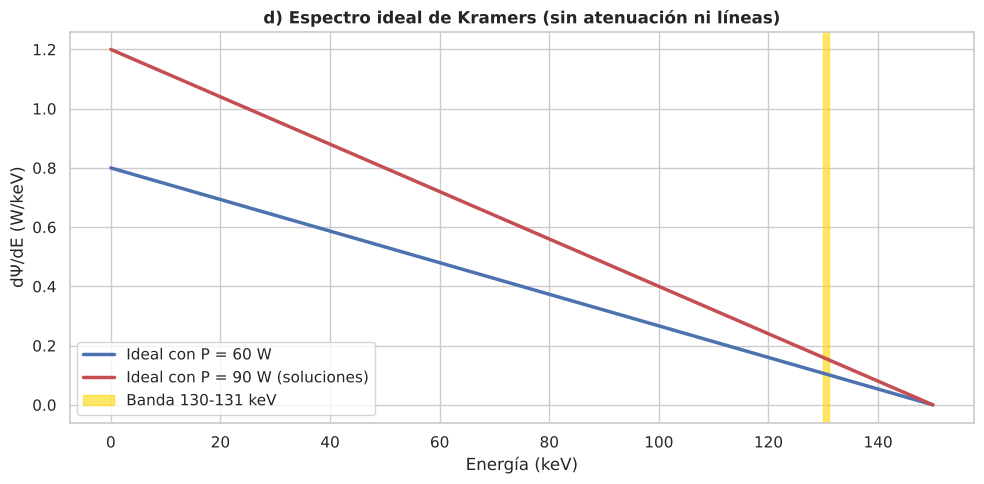

In [12]:
# =====================================================================
# 1. DATOS Y CÁLCULOS
# =====================================================================
V_kV, I_mA, eta = 150.0, 50.0, 0.008
E_K, E_L = 69.5, 11.5

E_maxX = V_kV
E_Ka = E_K - E_L
P_el = V_kV * 1e3 * I_mA * 1e-3
P_X = eta * P_el
P_term = P_el - P_X

def potencia_banda(P_ideal, E1, E2, Emax=E_maxX):
    k = 2 * P_ideal / Emax**2           # W/keV²
    return k * ((Emax - E1)**2 - (Emax - E2)**2) / 2

print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 7)                    ")
print("=====================================================================")
print(f"a) E_max = {E_maxX:.0f} keV")
print(f"b) E(Kα) = {E_Ka:.1f} keV")
print(f"c) P_eléctrica = {P_el/1e3:.2f} kW,  P_X = {P_X:.0f} W,  P_térmica = {P_term/1e3:.2f} kW")
for P_id, criterio in [(P_X, 'espectro ideal = 60 W'), (90.0, 'soluciones: ideal = 90 W')]:
    print(f"e) [{criterio}]  dΨ/dE(0) = {2*P_id/E_maxX:.2f} W/keV  ->  Ψ(130-131 keV) = {potencia_banda(P_id,130,131):.3f} W")
print("=====================================================================")

E = np.linspace(0, E_maxX, 500)
fig, ax = plt.subplots(figsize=(10, 5))
for P_id, color, etiqueta in [(P_X, '#4c72b0', 'Ideal con P = 60 W'), (90.0, '#c44e52', 'Ideal con P = 90 W (soluciones)')]:
    ax.plot(E, 2 * P_id / E_maxX**2 * (E_maxX - E), color=color, lw=2.5, label=etiqueta)
ax.axvspan(130, 131, color='gold', alpha=0.6, label='Banda 130-131 keV')
ax.set_xlabel('Energía (keV)'); ax.set_ylabel('dΨ/dE (W/keV)')
ax.set_title('d) Espectro ideal de Kramers (sin atenuación ni líneas)', fontweight='bold')
ax.legend(); plt.tight_layout(); plt.show()

#### **Bonus: Generador de espectros de rayos X**

Este widget genera un espectro **aproximado** de un tubo de rayos X con ánodo de tungsteno:
* Bremsstrahlung según Kramers, con la potencia total fijada por la eficiencia empírica $\eta \approx 1.1\times10^{-9}\,Z\,V$ (V en voltios).
* **Autoabsorción** en el ánodo (espesor equivalente de W ajustable, con su borde K a 69.5 keV) y **filtración** con aluminio. Los coeficientes de atenuación se aproximan con leyes de potencias ajustadas a los datos del NIST (sólo para fines ilustrativos).
* **Líneas características** $K_\alpha$ (58-59 keV) y $K_\beta$ (67 keV) cuando $V > 69.5$ kV, con intensidad aproximada.

Se muestran también la **energía media** del haz y su **capa hemirreductora** (HVL) en aluminio, magnitudes clave en radiodiagnóstico.

**Cuestiones:**
1. ¿Qué le ocurre al espectro cuando aumentas el filtrado? ¿Por qué se dice que el haz se "endurece"?
2. ¿Por qué no aparecen las líneas K del W con un tubo de mamografía (28 kV)?
3. ¿Cómo cambian la potencia de rayos X y la eficiencia al pasar de 80 a 150 kV?

In [13]:
def mu_rho_Al(E):        # cm²/g, E en keV (aproximación)
    return 0.15 + 26400 / E**3

def mu_rho_W(E):         # cm²/g, con borde K en 69.5 keV (aproximación)
    return np.where(E < E_K, 3.55e5 / E**2.8, 1.67e6 / E**2.8) + 0.1

def espectro_rayos_X(V, I_mA_w, W_um, Al_mm):
    E = np.linspace(1, V, 1500)
    dE = E[1] - E[0]
    eta_k = 1.1e-9 * 74 * V * 1e3
    P_brem = eta_k * V * 1e3 * I_mA_w * 1e-3                   # W
    ideal = 2 * P_brem / V**2 * (V - E)                         # W/keV
    T = np.exp(-mu_rho_W(E) * 19.3 * W_um * 1e-4 - mu_rho_Al(E) * 2.70 * Al_mm * 0.1)
    real = ideal * T
    if V > E_K:
        frac_K = 0.07 * ((V / E_K - 1) / (150 / E_K - 1))**1.6     # fracción aproximada
        for Ec, rel in [(59.3, 0.50), (58.0, 0.29), (67.2, 0.21)]:   # Kα1, Kα2, Kβ
            area = frac_K * P_brem * rel
            Tl = np.exp(-mu_rho_W(Ec) * 19.3 * W_um * 1e-4 - mu_rho_Al(Ec) * 2.70 * Al_mm * 0.1)
            real = real + area * Tl * np.exp(-0.5 * ((E - Ec) / 0.6)**2) / (np.sqrt(2 * np.pi) * 0.6)
    P_real = np.sum(real) * dE
    E_media = np.sum(E * real) / np.sum(real)
    # Capa hemirreductora en Al (por kerma aproximado ~ energía)
    f_HVL = lambda x: np.sum(real * np.exp(-mu_rho_Al(E) * 2.70 * x * 0.1)) / np.sum(real) - 0.5
    HVL = brentq(f_HVL, 1e-4, 200)
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(E, ideal, color='gray', ls='--', lw=1.5, label=f'Ideal (Kramers): {P_brem:.1f} W')
    ax.plot(E, real, color='#4c72b0', lw=2)
    ax.fill_between(E, real, color='#4c72b0', alpha=0.25, label=f'Emitido: {P_real:.1f} W')
    ax.axvline(E_media, color='#c44e52', ls=':', label=f'Energía media: {E_media:.1f} keV')
    ax.set_xlim(0, V * 1.02); ax.set_ylim(0, max(ideal.max(), real.max()) * 1.05)
    ax.set_xlabel('Energía (keV)'); ax.set_ylabel('dΨ/dE (W/keV)')
    ax.set_title(f'Tubo de W a {V:.0f} kV y {I_mA_w:.0f} mA  |  HVL = {HVL:.2f} mm Al', fontweight='bold')
    ax.legend(); plt.tight_layout(); plt.show()
    print(f"P eléctrica = {V*I_mA_w/1e3:.2f} kW  |  η (Kramers) = {100*eta_k:.2f}%  |  "
          f"Potencia emitida tras filtración = {P_real:.1f} W ({100*P_real/P_brem:.0f}% de la ideal)")

interact(espectro_rayos_X,
         V=widgets.FloatSlider(value=150, min=20, max=150, step=1, description='V (kV)', continuous_update=False),
         I_mA_w=widgets.FloatSlider(value=50, min=1, max=500, step=1, description='I (mA)', continuous_update=False),
         W_um=widgets.FloatSlider(value=5, min=0, max=30, step=0.5, description='W (µm)', continuous_update=False),
         Al_mm=widgets.FloatSlider(value=2.5, min=0, max=10, step=0.1, description='Al (mm)', continuous_update=False));

---
### **Resumen de la Hoja 5**

| Concepto | Expresión | Problemas |
| :--- | :--- | :--- |
| Potencia de un haz | $P = VI$, $\dot{N} = I/e$ | 1, 3 |
| Cinemática relativista | $\gamma = E/mc^2$, $1 - \beta \approx 1/2\gamma^2$ | 2, 6 |
| Radio en un campo magnético | $R[\text{m}] = p[\text{GeV}/c]/(0.2998\,B[\text{T}])$ | 2, 4 |
| Ciclotrón | $\omega = qB/m$ (independiente de E si no es relativista) | 4 |
| Luminosidad | $\mathcal{L} = N_1N_2 f n_b/S$, $\dot{n} = \mathcal{L}\sigma$ | 2 |
| Umbral de reacción (blanco fijo) | $T_{th} = -Q(1 + m_1/m_2)$ | 3 |
| Energía disponible | $\sqrt{s}$: $\sqrt{2Emc^2}$ (blanco fijo) vs $2E$ (colisionador) | 5, 6 |
| Tubo de rayos X | $E_{max} = eV$, Kramers $d\Psi/dE \propto (E_{max} - E)$, $\eta \approx 10^{-9}ZV$ | 7 |